# Actividad 9: Regresión Logística Multinomial
**Materia:** Ciencia de Datos Aplicada (TI3002C)  
**Proyecto Reto:** CLV México (Comercializadora de Insumos y Equipos Dentales)  
**Autor:** Andre Guillermo Carvajal Flores (A01738830)  
**Fecha:** Noviembre 2026  

---

### Objetivo General
Modelar, evaluar e interpretar la clasificación multiclase ($K \ge 3$) mediante **Regresión Logística Multinomial** sobre los datos comerciales y de inventario del socio formador **CLV México**, contrastando los resultados supervisados con los segmentos obtenidos previamente mediante técnicas de agrupamiento no supervisado (*Clustering K-Means / Clasificación ABC*).

### Alcance de la Actividad
1. **Preprocesamiento riguroso:** Auditoría y tratamiento de datos nulos, filtrado de registros no comerciales, detección y tratamiento de datos atípicos (*Outliers*) mediante el método del Rango Intercuartílico (IQR) y transformaciones logarítmicas.
2. **Construcción y análisis de 5 variables categóricas multiclase ($K \ge 3$):**
   * *Variable 1:* Clasificación ABC de Artículos (*Clases A, B y C*).
   * *Variable 2:* Nivel de Cobertura / Salud de Inventario (*Crítico/Desabasto, Óptimo, Sobreinventario*).
   * *Variable 3:* Macro-Segmentos de Rotación del Catálogo (*Puente con Clustering K-Means*).
   * *Variable 4:* Rango de Ticket de Transacción (*Ticket Bajo, Ticket Medio, Ticket Alto*).
   * *Variable 5:* Nivel de Volumen de Pedido (*Compra Unitaria, Volumen Moderado, Volumen Alto*).
3. **Métricas de Clasificación:** Para cada una de las 5 variables, evaluar y visualizar la **Matriz de Confusión**, la **Exactitud (Accuracy)**, la **Precisión (Precision)** y la **Sensibilidad (Recall / Sensibilidad)** tanto por clase como ponderada (*Weighted*), concluyendo con un cuadro comparativo y recomendaciones estratégicas para CLV.


---
## 1. Importación de Librerías y Configuración del Entorno
Importamos el ecosistema estándar para análisis numérico, manipulación de datos, modelado multiclase con `scikit-learn` y visualización estadística avanzada.


In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

# Modelado supervisado y preprocesamiento
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Estilo gráfico homogéneo y profesional
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (8, 4.5)
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 11
plt.rcParams["axes.titleweight"] = "bold"

print("✓ Entorno configurado correctamente para Regresión Logística Multinomial.")


✓ Entorno configurado correctamente para Regresión Logística Multinomial.


---
## 2. Carga de Datos y Auditoría Estructural
Cargamos las bases provistas por el socio formador: el histórico comercial transaccional (`Ventas_CLV_2022_2026.csv`), las existencias de almacén (`Existencias_04_09_2026.csv`) y la tabla maestra de segmentación de SKUs consolidada (`segmentacion_sku.csv`).


In [2]:
# Rutas relativas compatibles con el entorno de trabajo
RUTA_VENTAS = Path("datos/Ventas_CLV_2022_2026.csv")
RUTA_EXISTENCIAS = Path("datos/Existencias_04_09_2026.csv")
RUTA_SKU = Path("datos/segmentacion_sku.csv")

# Verificamos existencia y cargamos
df_ventas_raw = pd.read_csv(RUTA_VENTAS, low_memory=False)
df_exist_raw = pd.read_csv(RUTA_EXISTENCIAS)
df_sku_raw = pd.read_csv(RUTA_SKU)

print(f"Dimensiones Ventas Transaccionales : {df_ventas_raw.shape[0]:,} filas × {df_ventas_raw.shape[1]} columnas")
print(f"Dimensiones Existencias Almacén     : {df_exist_raw.shape[0]:,} filas × {df_exist_raw.shape[1]} columnas")
print(f"Dimensiones Catálogo Maestro SKUs   : {df_sku_raw.shape[0]:,} filas × {df_sku_raw.shape[1]} columnas")


Dimensiones Ventas Transaccionales : 114,501 filas × 15 columnas
Dimensiones Existencias Almacén     : 2,950 filas × 6 columnas
Dimensiones Catálogo Maestro SKUs   : 5,528 filas × 22 columnas


---
## 3. Preprocesamiento de Datos: Nulos, Outliers y Transformaciones

### 3.1 Tratamiento de Nulos y Filtrado Comercial
En el histórico de ventas se identifican y separan registros con montos o unidades menores o iguales a cero (bonificaciones, muestras o garantías no comerciales). En la tabla de catálogo se imputan nulos en métricas continuas de inventario.


In [3]:
# 1. Auditoría de nulos en Ventas
nulos_ventas = df_ventas_raw.isna().sum()
pct_nulos = (df_ventas_raw.isna().mean() * 100).round(2)
tabla_nulos = pd.DataFrame({"Nulos": nulos_ventas, "Porcentaje_%": pct_nulos})
print("--- Diagnóstico de Nulos en Ventas Transaccionales ---")
display(tabla_nulos[tabla_nulos["Nulos"] > 0])

# 2. Filtrado de registros comerciales válidos (precio > 0, unidades > 0, total_neto > 0)
filtro_comercial = (
    (df_ventas_raw["precio_unitario"] > 0) &
    (df_ventas_raw["total_unidades"] > 0) &
    (df_ventas_raw["total_neto"] > 0)
)
df_ventas = df_ventas_raw[filtro_comercial].copy()
descartados = len(df_ventas_raw) - len(df_ventas)
print(f"Filas no comerciales descartadas: {descartados:,} ({descartados/len(df_ventas_raw)*100:.2f}%)")
print(f"Base transaccional limpia para modelado: {len(df_ventas):,} filas.")

# 3. Preparación de catálogo SKU
df_sku = df_sku_raw.copy()
df_sku['existencias'] = df_sku['existencias'].fillna(0)
df_sku['demanda_12m'] = df_sku['demanda_12m'].fillna(0)
df_sku['costo_unitario'] = df_sku['costo_unitario'].fillna(df_sku['costo_unitario'].median())
df_sku['meses_sin_demanda'] = df_sku['meses_sin_demanda'].fillna(12)


--- Diagnóstico de Nulos en Ventas Transaccionales ---


,Nulos,Porcentaje_%
cp,5188,4.53


Filas no comerciales descartadas: 4,729 (4.13%)
Base transaccional limpia para modelado: 109,772 filas.


### 3.2 Detección de Outliers mediante Rango Intercuartílico (IQR)
Las variables económicas y de abastecimiento de CLV presentan distribuciones con asimetría positiva muy pronunciada (pocos equipos médicos con costo o volumen extremadamente alto).
Calculamos los límites superior e inferior por IQR:
$$\text{IQR} = Q_3 - Q_1, \quad \text{Límite Superior} = Q_3 + 1.5 \times \text{IQR}$$


In [4]:
variables_eval_iqr = ['precio_unitario', 'total_unidades', 'total_neto']
resumen_iqr = []

for col in variables_eval_iqr:
    q25 = df_ventas[col].quantile(0.25)
    mediana = df_ventas[col].median()
    q75 = df_ventas[col].quantile(0.75)
    iqr = q75 - q25
    lim_sup = q75 + 1.5 * iqr
    outliers_cnt = (df_ventas[col] > lim_sup).sum()
    pct = round(outliers_cnt / len(df_ventas) * 100, 2)
    
    resumen_iqr.append({
        "Variable": col,
        "Q1 (25%)": round(q25, 2),
        "Mediana": round(mediana, 2),
        "Q3 (75%)": round(q75, 2),
        "Límite Sup IQR": round(lim_sup, 2),
        "Conteo Outliers": f"{outliers_cnt:,}",
        "Porcentaje Outliers": f"{pct}%"
    })

display(pd.DataFrame(resumen_iqr))


,Variable,Q1 (25%),Mediana,Q3 (75%),Límite Sup IQR,Conteo Outliers,Porcentaje Outliers
0,precio_unitario,163.79,401.90,1129.31,2577.59,"9,310",8.48%
1,total_unidades,1.00,1.00,2.00,3.50,"16,080",14.65%
2,total_neto,215.52,689.64,1958.62,4573.27,"10,683",9.73%


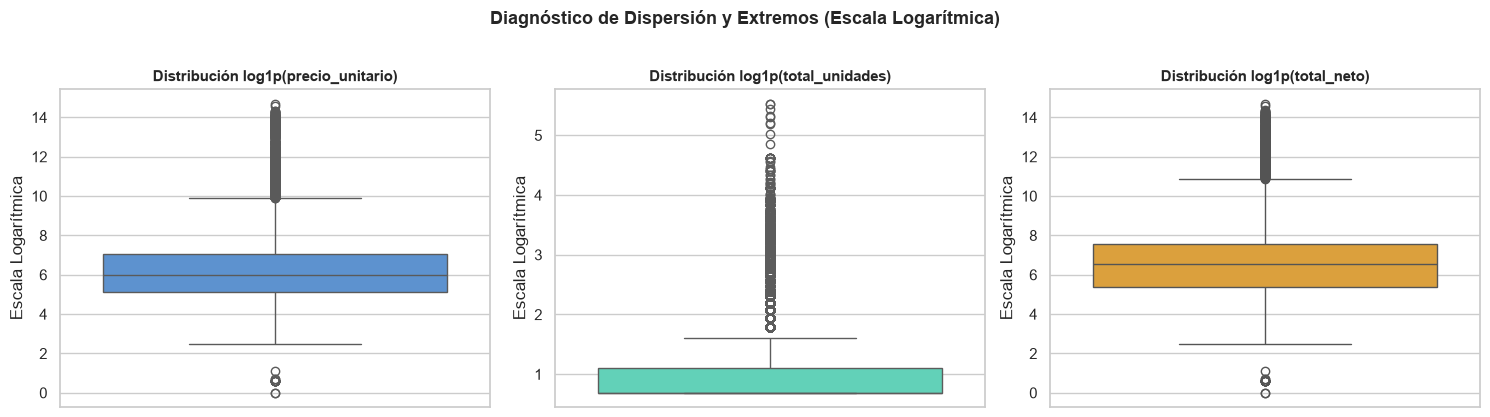

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
palette_boxes = ["#4A90E2", "#50E3C2", "#F5A623"]

for i, col in enumerate(variables_eval_iqr):
    sns.boxplot(y=np.log1p(df_ventas[col]), ax=axes[i], color=palette_boxes[i])
    axes[i].set_title(f"Distribución log1p({col})")
    axes[i].set_ylabel("Escala Logarítmica")

plt.suptitle("Diagnóstico de Dispersión y Extremos (Escala Logarítmica)", fontsize=13, fontweight="bold", y=1.03)
plt.tight_layout()
plt.show()


---
## 4. Fundamentación Matemática: Regresión Logística Multinomial (Softmax)

Cuando la variable respuesta $Y$ posee $K \ge 3$ categorías nominales o politómicas, la probabilidad condicional de pertenecer a la clase $k$ dado el vector de predictores $X$ se modela mediante la función **Softmax**:

$$P(Y = k \mid X) = \frac{e^{\beta_k^T X}}{\sum_{j=1}^{K} e^{\beta_j^T X}}$$

Donde:
* $\beta_k$ representa el vector de coeficientes para la categoría $k$.
* La optimización se realiza maximizando la log-verosimilitud mediante la función de pérdida de **Entropía Cruzada Categórica** (*Categorical Cross-Entropy*):

$$\mathcal{L}(\beta) = - \sum_{i=1}^{N} \sum_{k=1}^{K} y_{ik} \ln \left( P(Y_i = k \mid X_i) \right)$$

### Métricas de Evaluación Multiclase
A diferencia de los modelos binarios, en clasificación multinomial evaluamos:
1. **Exactitud Global (*Accuracy*):** Porcentaje total de clasificaciones correctas.
2. **Sensibilidad (*Recall*) por clase:** Capacidad del modelo para identificar a los miembros reales de la clase $k$:
   $$\text{Recall}_k = \frac{\text{Verdaderos Positivos}_k}{\text{Verdaderos Positivos}_k + \text{Falsos Negativos}_k}$$
3. **Precisión (*Precision*) por clase:** Confiabilidad cuando el modelo predice la clase $k$:
   $$\text{Precision}_k = \frac{\text{Verdaderos Positivos}_k}{\text{Verdaderos Positivos}_k + \text{Falsos Positivos}_k}$$
4. **Promedio Ponderado (*Weighted Average*):** Ponderación de cada métrica según la frecuencia real de cada categoría en la muestra de prueba.


In [6]:
# Función modular para entrenar, predecir y tabular métricas multiclase de forma estandarizada
def evaluar_modelo_multinomial(X, y, nombre_variable, class_weight='balanced'):
    # División Train/Test 80/20 estratificada
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.20, random_state=42, stratify=y
    )
    
    # Estandarización de características
    scaler = StandardScaler()
    X_train_sc = scaler.fit_transform(X_train)
    X_test_sc = scaler.transform(X_test)
    
    # Ajuste de Regresión Logística Multinomial
    modelo = LogisticRegression(
        solver='lbfgs',
        max_iter=1000,
        class_weight=class_weight,
        random_state=42
    )
    modelo.fit(X_train_sc, y_train)
    y_pred = modelo.predict(X_test_sc)
    
    # Métricas globales
    acc = accuracy_score(y_test, y_pred)
    prec_w = precision_score(y_test, y_pred, average='weighted', zero_division=0)
    rec_w = recall_score(y_test, y_pred, average='weighted', zero_division=0)
    f1_w = f1_score(y_test, y_pred, average='weighted', zero_division=0)
    
    # Desglose por clase
    etiquetas = np.unique(y)
    report_dict = classification_report(y_test, y_pred, output_dict=True, zero_division=0)
    
    filas_clases = []
    for etq in etiquetas:
        filas_clases.append({
            "Clase": str(etq),
            "Sensibilidad (Recall)": f"{report_dict[str(etq)]['recall'] * 100:.2f}%",
            "Precisión": f"{report_dict[str(etq)]['precision'] * 100:.2f}%",
            "F1-Score": round(report_dict[str(etq)]['f1-score'], 3),
            "Soporte (Test)": int(report_dict[str(etq)]['support'])
        })
    
    df_clases = pd.DataFrame(filas_clases)
    
    # Matriz de confusión
    cm = confusion_matrix(y_test, y_pred, labels=etiquetas)
    
    # Gráficos
    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    
    # Distribución general
    y.value_counts(normalize=True).mul(100).loc[etiquetas].plot(
        kind='bar', ax=axes[0], color='#2E86C1', edgecolor='black'
    )
    axes[0].set_title(f"Distribución de Clases: {nombre_variable}")
    axes[0].set_ylabel("Frecuencia (%)")
    axes[0].set_xlabel("Categoría")
    axes[0].tick_params(axis='x', rotation=20)
    
    # Heatmap Matriz de Confusión
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=etiquetas, yticklabels=etiquetas, ax=axes[1])
    axes[1].set_title(f"Matriz de Confusión: {nombre_variable}")
    axes[1].set_xlabel("Predicción del Modelo")
    axes[1].set_ylabel("Valor Real")
    
    plt.tight_layout()
    plt.show()
    
    print(f"=== RESULTADOS GLOBALES: {nombre_variable.upper()} ===")
    print(f"Exactitud (Accuracy)   : {acc*100:.2f}%")
    print(f"Sensibilidad Ponderada : {rec_w*100:.2f}%")
    print(f"Precisión Ponderada    : {prec_w*100:.2f}%")
    print(f"F1-Score Ponderado     : {f1_w:.3f}")
    print("\nDesglose Detallado por Categoría:")
    display(df_clases)
    
    return {
        "Variable": nombre_variable,
        "Accuracy_%": round(acc * 100, 2),
        "Sensibilidad_Ponderada_%": round(rec_w * 100, 2),
        "Precision_Ponderada_%": round(prec_w * 100, 2),
        "F1_Weighted": round(f1_w, 3)
    }

registro_resultados = []


---
## 5. Variable 1: Clasificación ABC de Artículos del Catálogo
* **Propósito:** Evaluar si las variables operativas fundamentales (`demanda_12m`, `costo_unitario`, `existencias`, `meses_sin_demanda`) son suficientes para que una regresión logística multinomial aprenda las fronteras de valor acumulado de Pareto.
* **Categorías:** 
  * Clase **A** (Artículos de alto impacto económico, ~80% de valor).
  * Clase **B** (Artículos de impacto moderado, ~15% de valor).
  * Clase **C** (Artículos de bajo impacto económico acumulado, ~5% de valor).


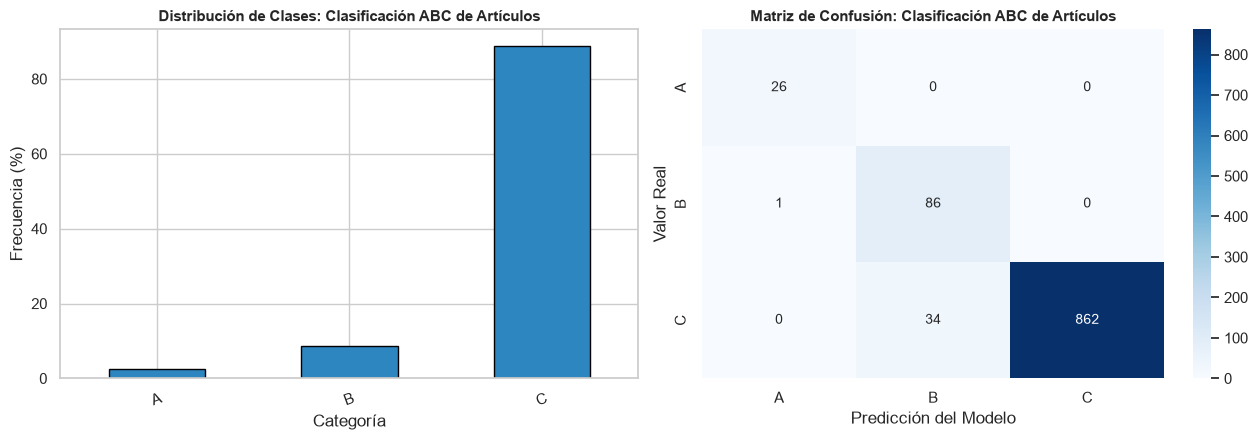

=== RESULTADOS GLOBALES: CLASIFICACIÓN ABC DE ARTÍCULOS ===
Exactitud (Accuracy)   : 96.53%
Sensibilidad Ponderada : 96.53%
Precisión Ponderada    : 97.46%
F1-Score Ponderado     : 0.968

Desglose Detallado por Categoría:


,Clase,Sensibilidad (Recall),Precisión,F1-Score,Soporte (Test)
0,A,100.00%,96.30%,0.981,26
1,B,98.85%,71.67%,0.831,87
2,C,96.21%,100.00%,0.981,896


In [7]:
# Filtramos catálogo con ABC válido
df_v1 = df_sku[df_sku['clase_abc'].isin(['A', 'B', 'C'])].copy()

# Variables predictoras continuas transformadas logarítmicamente
X_v1 = np.log1p(df_v1[['demanda_12m', 'costo_unitario', 'existencias', 'meses_sin_demanda']])
y_v1 = df_v1['clase_abc']

res_v1 = evaluar_modelo_multinomial(X_v1, y_v1, "Clasificación ABC de Artículos")
registro_resultados.append(res_v1)


---
## 6. Variable 2: Salud del Stock / Nivel de Cobertura de Almacén
* **Propósito:** Predecir si un producto se encuentra en condición de riesgo operativo o exceso de capital inmovilizado con base en sus niveles de demanda anual, rotación de salida y costo.
* **Categorías:**
  * **Crítico / Desabasto:** Cobertura $< 1.0$ mes (riesgo inminente de faltante ante clientes).
  * **Óptimo:** Cobertura entre $1.0$ y $4.0$ meses (amortiguador ideal de servicio).
  * **Sobreinventario:** Cobertura $> 4.0$ meses (dinero detenido con baja rotación).


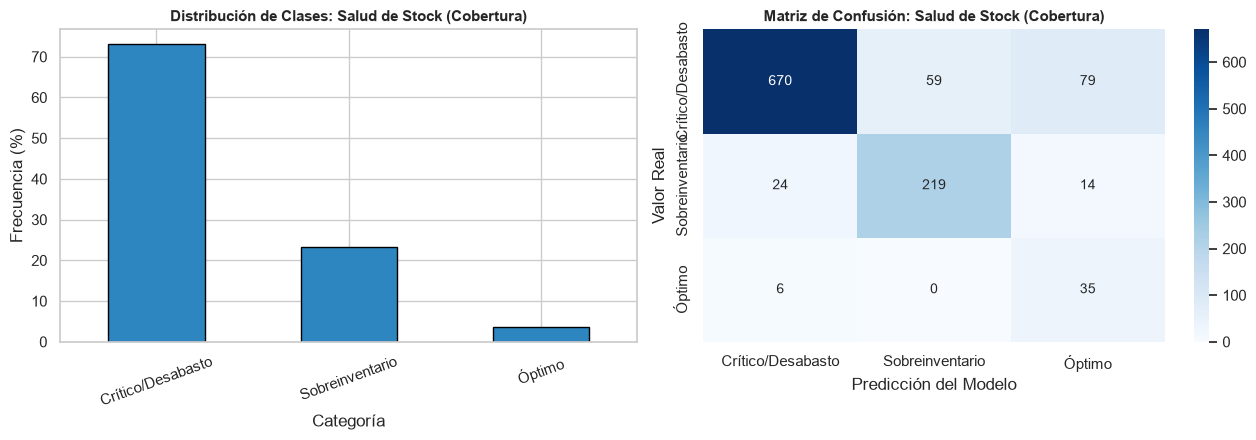

=== RESULTADOS GLOBALES: SALUD DE STOCK (COBERTURA) ===
Exactitud (Accuracy)   : 83.54%
Sensibilidad Ponderada : 83.54%
Precisión Ponderada    : 89.24%
F1-Score Ponderado     : 0.855

Desglose Detallado por Categoría:


,Clase,Sensibilidad (Recall),Precisión,F1-Score,Soporte (Test)
0,Crítico/Desabasto,82.92%,95.71%,0.889,808
1,Sobreinventario,85.21%,78.78%,0.819,257
2,Óptimo,85.37%,27.34%,0.414,41


In [8]:
def categorizar_cobertura(cob):
    if pd.isna(cob) or cob < 1.0:
        return 'Crítico/Desabasto'
    elif cob <= 4.0:
        return 'Óptimo'
    else:
        return 'Sobreinventario'

df_v2 = df_sku.copy()
df_v2['salud_stock'] = df_v2['cobertura_meses'].apply(categorizar_cobertura)

# Variables predictoras
X_v2 = np.log1p(df_v2[['demanda_12m', 'costo_unitario', 'existencias', 'meses_sin_demanda']])
y_v2 = df_v2['salud_stock']

res_v2 = evaluar_modelo_multinomial(X_v2, y_v2, "Salud de Stock (Cobertura)")
registro_resultados.append(res_v2)


---
## 7. Variable 3: Macro-Segmentos de Rotación (Puente con Clustering K-Means)
* **Propósito:** **Conexión directa con la etapa de Clustering.** Evaluamos qué tan bien un modelo lineal multiclase supervisado es capaz de aprender y reproducir las fronteras naturales generadas por el algoritmo no supervisado (K-Means/Ward).
* **Categorías:**
  * **Alta Rotación (C1):** Consumibles clave con salidas casi mensuales.
  * **Rotación Moderada (C2 / C4):** Consumibles medianos y demanda regular.
  * **Baja Rotación / Intermitente (C3):** Salidas muy espaciadas en el tiempo.
  * **Alto Valor / Especializado (C5):** Equipos de alto costo unitario y ventas esporádicas.


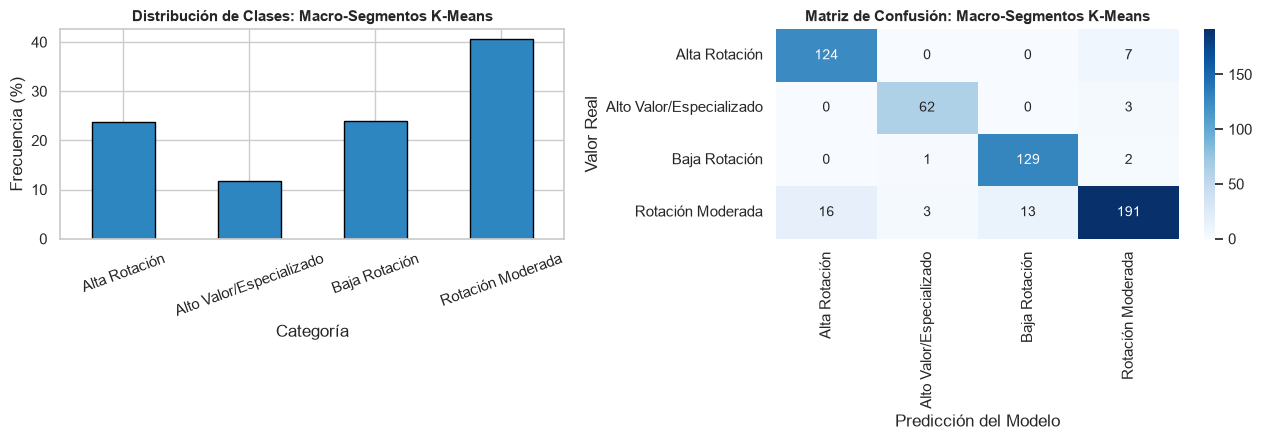

=== RESULTADOS GLOBALES: MACRO-SEGMENTOS K-MEANS ===
Exactitud (Accuracy)   : 91.83%
Sensibilidad Ponderada : 91.83%
Precisión Ponderada    : 91.98%
F1-Score Ponderado     : 0.918

Desglose Detallado por Categoría:


,Clase,Sensibilidad (Recall),Precisión,F1-Score,Soporte (Test)
0,Alta Rotación,94.66%,88.57%,0.915,131
1,Alto Valor/Especializado,95.38%,93.94%,0.947,65
2,Baja Rotación,97.73%,90.85%,0.942,132
3,Rotación Moderada,85.65%,94.09%,0.897,223


In [9]:
df_v3 = df_sku[df_sku['segmento'].isin(['C1', 'C2', 'C3', 'C4', 'C5'])].copy()
map_clustering = {
    'C1': 'Alta Rotación',
    'C2': 'Rotación Moderada',
    'C4': 'Rotación Moderada',
    'C3': 'Baja Rotación',
    'C5': 'Alto Valor/Especializado'
}
df_v3['macro_cluster'] = df_v3['segmento'].map(map_clustering)

X_v3 = np.log1p(df_v3[['demanda_12m', 'costo_unitario', 'adi_24m', 'cv2_24m', 'meses_sin_demanda']])
y_v3 = df_v3['macro_cluster']

res_v3 = evaluar_modelo_multinomial(X_v3, y_v3, "Macro-Segmentos K-Means")
registro_resultados.append(res_v3)


---
## 8. Variable 4: Rango de Ticket Transaccional
* **Propósito:** Predecir a nivel transaccional qué tipo de pedido comercial se está generando (si es una compra menor de mostrador, una orden estándar de clínica o una adquisición mayorista) a partir del precio del insumo y las unidades requeridas.
* **Categorías:** Terciles homogéneos de facturación neta:
  * **Ticket Menor:** Tercil inferior ($33.3\%$ de transacciones).
  * **Ticket Medio:** Tercil medio ($33.3\%$ a $66.6\%$).
  * **Ticket Alto:** Tercil superior ($> 66.6\%$).


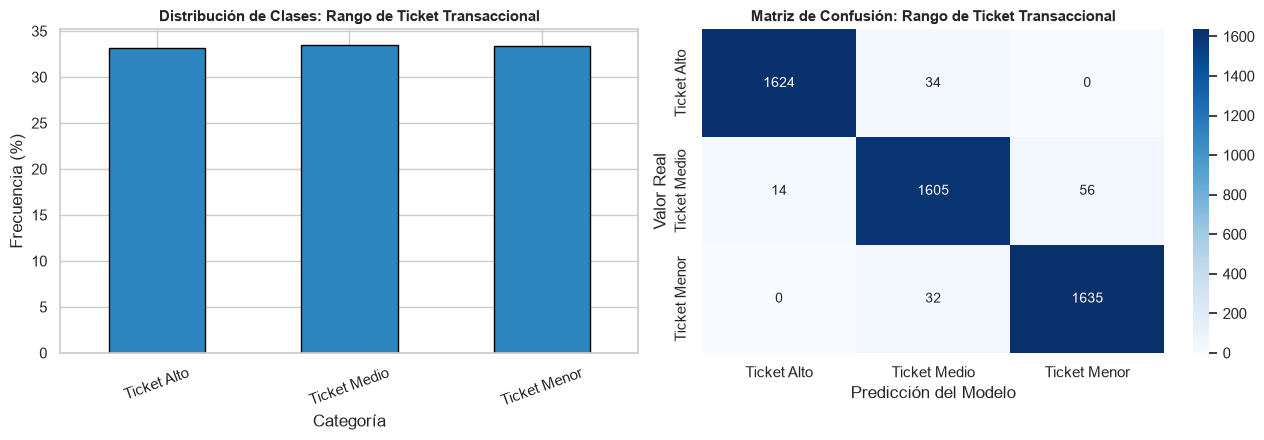

=== RESULTADOS GLOBALES: RANGO DE TICKET TRANSACCIONAL ===
Exactitud (Accuracy)   : 97.28%
Sensibilidad Ponderada : 97.28%
Precisión Ponderada    : 97.29%
F1-Score Ponderado     : 0.973

Desglose Detallado por Categoría:


,Clase,Sensibilidad (Recall),Precisión,F1-Score,Soporte (Test)
0,Ticket Alto,97.95%,99.15%,0.985,1658
1,Ticket Medio,95.82%,96.05%,0.959,1675
2,Ticket Menor,98.08%,96.69%,0.974,1667


In [10]:
# Muestra aleatoria estratificada representativa para eficiencia de cómputo transaccional
df_v4 = df_ventas.sample(n=25000, random_state=42).copy()

q33 = df_v4['total_neto'].quantile(0.333)
q66 = df_v4['total_neto'].quantile(0.666)

def asignar_ticket(val):
    if val <= q33:
        return 'Ticket Menor'
    elif val <= q66:
        return 'Ticket Medio'
    else:
        return 'Ticket Alto'

df_v4['rango_ticket'] = df_v4['total_neto'].apply(asignar_ticket)

X_v4 = np.log1p(df_v4[['precio_unitario', 'total_unidades']])
y_v4 = df_v4['rango_ticket']

res_v4 = evaluar_modelo_multinomial(X_v4, y_v4, "Rango de Ticket Transaccional")
registro_resultados.append(res_v4)


---
## 9. Variable 5: Nivel de Volumen de Pedido Comercial
* **Propósito:** Ampliar la dicotomización previa de la evaluación lineal/logística hacia una escala multiclase que permita anticipar el tipo de despacho en almacén (unidades sueltas vs paquetes de mayoreo).
* **Categorías:**
  * **Compra Unitaria:** 1 unidad pedida ($61.5\%$ de órdenes).
  * **Volumen Moderado:** 2 a 5 unidades ($31.0\%$ de órdenes).
  * **Volumen Alto / Mayoreo:** $> 5$ unidades ($7.5\%$ de órdenes).


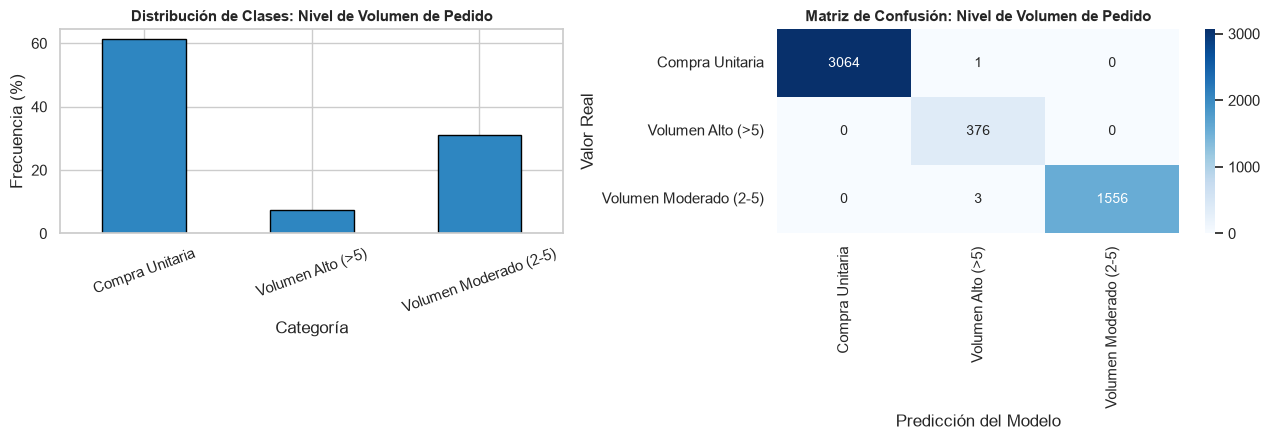

=== RESULTADOS GLOBALES: NIVEL DE VOLUMEN DE PEDIDO ===
Exactitud (Accuracy)   : 99.92%
Sensibilidad Ponderada : 99.92%
Precisión Ponderada    : 99.92%
F1-Score Ponderado     : 0.999

Desglose Detallado por Categoría:


,Clase,Sensibilidad (Recall),Precisión,F1-Score,Soporte (Test)
0,Compra Unitaria,99.97%,100.00%,1.000,3065
1,Volumen Alto (>5),100.00%,98.95%,0.995,376
2,Volumen Moderado (2-5),99.81%,100.00%,0.999,1559


In [11]:
df_v5 = df_ventas.sample(n=25000, random_state=42).copy()

def categorizar_volumen(unidades):
    if unidades == 1:
        return 'Compra Unitaria'
    elif unidades <= 5:
        return 'Volumen Moderado (2-5)'
    else:
        return 'Volumen Alto (>5)'

df_v5['tipo_volumen'] = df_v5['total_unidades'].apply(categorizar_volumen)

# Predecimos a partir del total facturado y el precio del insumo
X_v5 = np.log1p(df_v5[['precio_unitario', 'total_neto']])
y_v5 = df_v5['tipo_volumen']

res_v5 = evaluar_modelo_multinomial(X_v5, y_v5, "Nivel de Volumen de Pedido")
registro_resultados.append(res_v5)


---
## 10. Cuadro Comparativo Integrador de las 5 Variables Categóricas

Consolidamos las métricas obtenidas por los 5 modelos de Regresión Logística Multinomial:


,Variable,Accuracy_%,Sensibilidad_Ponderada_%,Precision_Ponderada_%,F1_Weighted
0,Clasificación ABC de Artículos,96.53,96.53,97.46,0.968
1,Salud de Stock (Cobertura),83.54,83.54,89.24,0.855
2,Macro-Segmentos K-Means,91.83,91.83,91.98,0.918
3,Rango de Ticket Transaccional,97.28,97.28,97.29,0.973
4,Nivel de Volumen de Pedido,99.92,99.92,99.92,0.999


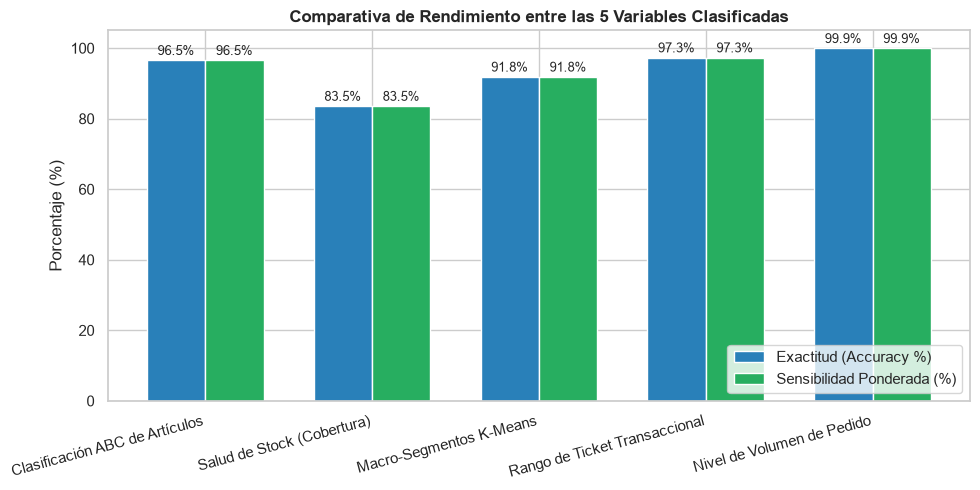

In [12]:
df_resumen_final = pd.DataFrame(registro_resultados)
display(df_resumen_final)

# Gráfico de barras comparativo de Exactitud vs Sensibilidad Ponderada
fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(df_resumen_final))
width = 0.35

ax.bar(x - width/2, df_resumen_final['Accuracy_%'], width, label='Exactitud (Accuracy %)', color='#2980B9')
ax.bar(x + width/2, df_resumen_final['Sensibilidad_Ponderada_%'], width, label='Sensibilidad Ponderada (%)', color='#27AE60')

ax.set_ylabel('Porcentaje (%)')
ax.set_title('Comparativa de Rendimiento entre las 5 Variables Clasificadas', fontsize=12, fontweight='bold')
ax.set_xticks(x)
ax.set_xticklabels(df_resumen_final['Variable'], rotation=15, ha='right')
ax.set_ylim(0, 105)
ax.legend(loc='lower right')

for i in x:
    ax.text(i - width/2, df_resumen_final['Accuracy_%'][i] + 1.5, f"{df_resumen_final['Accuracy_%'][i]:.1f}%", ha='center', fontsize=9)
    ax.text(i + width/2, df_resumen_final['Sensibilidad_Ponderada_%'][i] + 1.5, f"{df_resumen_final['Sensibilidad_Ponderada_%'][i]:.1f}%", ha='center', fontsize=9)

plt.tight_layout()
plt.show()


---
## 10. Comparación Profunda: Clustering K-Means (No Supervisado) vs. Regresión Logística Multinomial (Supervisada)

En esta sección realizamos una **comparación directa, matemática y visual** entre el trabajo previo de **Clustering de SKUs** y los modelos de **Regresión Logística Multinomial** recién ajustados.

### 10.1 Comparativa de Variables y Formulación Matemática

| Criterio | Clustering de Inventario (Trabajo Previo) | Regresión Logística Multinomial (Actividad 9) |
| :--- | :--- | :--- |
| **Paradigma** | **No Supervisado** (Descubrimiento de estructura latente). | **Supervisado** (Optimización de fronteras de decisión probabilísticas). |
| **Función Objetivo** | Minimizar inercia intra-cluster: $\min \sum_{k=1}^K \sum_{i \in S_k} \|x_i - \mu_k\|^2$. | Maximizar verosimilitud Softmax: $\max \sum_{i=1}^N \sum_{k=1}^K y_{ik} \ln(P(Y_i=k \mid X_i))$. |
| **Variables de Entrada ($X$)** | `demanda_12m` (log1p), `costo_unitario` (log), `adi_24m` (log), `cv2_24m` (log1p), `meses_sin_demanda`. | Mismas variables operativas estandarizadas (`StandardScaler`) hacia variables objetivo multiclase. |
| **Variable Objetivo ($Y$)** | **Ninguna**. El algoritmo no conoce clases a priori. | **Discreta multiclase** ($K \ge 3$): Clase ABC, Salud de Stock, Macro-Segmentos, etc. |
| **Tipo de Salida** | Asignación dura a un cluster (partición de Voronoi). | Vector de probabilidades continuas $P(Y=k \mid X)$ vía Softmax con suma igual a 1. |
| **Inferencia para Nuevos SKUs** | Requiere recalcular distancias euclidianas a los centroides $\mu_k$. | Inferencia instantánea mediante el producto punto $\beta_k^T X$ (ideal para ERP Odoo). |


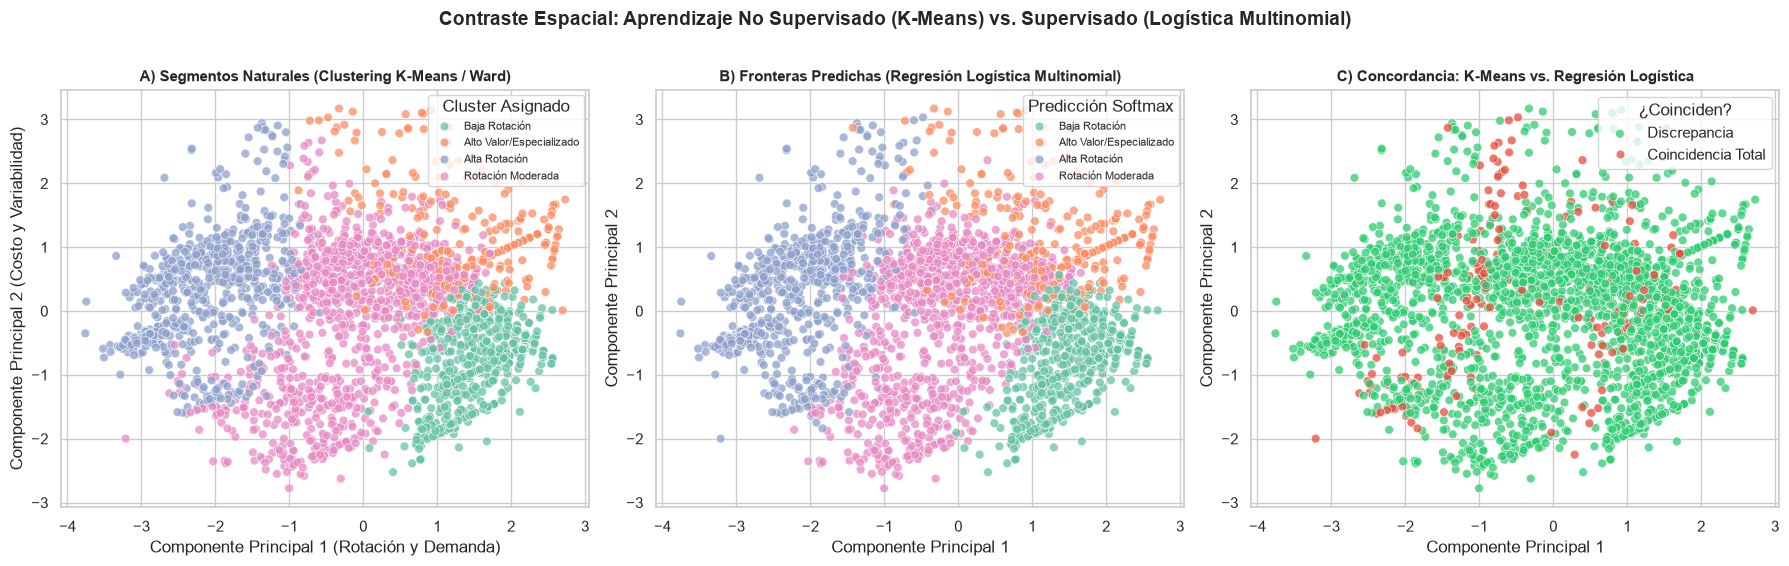

=== RESULTADOS DEL CONTRASTE ===
Concordancia Global entre K-Means y Regresión Logística: 93.89%

Matriz Cruzada: Segmentos Reales de Clustering vs. Predicción de Regresión Logística:


prediccion_logistica,Alta Rotación,Alto Valor/Especializado,Baja Rotación,Rotación Moderada,All
macro_cluster_real,,,,,
Alta Rotación,616,2,0,37,655
Alto Valor/Especializado,2,318,1,3,324
Baja Rotación,0,2,643,12,657
Rotación Moderada,58,29,22,1006,1115
All,676,351,666,1058,2751


In [13]:
# Comparación Visual en el Espacio Reducido de Componentes Principales (PCA: PC1 vs PC2)
df_comp = df_sku[df_sku['segmento'].isin(['C1', 'C2', 'C3', 'C4', 'C5']) & df_sku['pc1'].notna()].copy()

# Predecimos con el modelo de macro-segmentos ajustado en la Variable 3
map_clustering = {'C1': 'Alta Rotación', 'C2': 'Rotación Moderada', 'C4': 'Rotación Moderada', 'C3': 'Baja Rotación', 'C5': 'Alto Valor/Especializado'}
df_comp['macro_cluster_real'] = df_comp['segmento'].map(map_clustering)

X_comp_raw = np.log1p(df_comp[['demanda_12m', 'costo_unitario', 'adi_24m', 'cv2_24m', 'meses_sin_demanda']])
scaler_comp = StandardScaler()
X_comp_sc = scaler_comp.fit_transform(X_comp_raw)

modelo_comp = LogisticRegression(solver='lbfgs', max_iter=1000, class_weight='balanced', random_state=42)
modelo_comp.fit(X_comp_sc, df_comp['macro_cluster_real'])
df_comp['prediccion_logistica'] = modelo_comp.predict(X_comp_sc)
df_comp['coincide'] = (df_comp['macro_cluster_real'] == df_comp['prediccion_logistica'])

# Gráfica Comparativa Lado a Lado
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))

# 1. Agrupamiento Original de Clustering (K-Means)
sns.scatterplot(
    data=df_comp, x='pc1', y='pc2', hue='macro_cluster_real',
    palette='Set2', alpha=0.75, s=40, ax=axes[0]
)
axes[0].set_title("A) Segmentos Naturales (Clustering K-Means / Ward)", fontweight='bold')
axes[0].set_xlabel("Componente Principal 1 (Rotación y Demanda)")
axes[0].set_ylabel("Componente Principal 2 (Costo y Variabilidad)")
axes[0].legend(title="Cluster Asignado", loc='upper right', fontsize=8)

# 2. Clasificación Predicha por Regresión Logística Multinomial
sns.scatterplot(
    data=df_comp, x='pc1', y='pc2', hue='prediccion_logistica',
    palette='Set2', alpha=0.75, s=40, ax=axes[1]
)
axes[1].set_title("B) Fronteras Predichas (Regresión Logística Multinomial)", fontweight='bold')
axes[1].set_xlabel("Componente Principal 1")
axes[1].set_ylabel("Componente Principal 2")
axes[1].legend(title="Predicción Softmax", loc='upper right', fontsize=8)

# 3. Discrepancias / Coincidencias entre Ambos Enfoques
sns.scatterplot(
    data=df_comp, x='pc1', y='pc2', hue='coincide',
    palette={True: '#2ECC71', False: '#E74C3C'}, alpha=0.75, s=40, ax=axes[2]
)
axes[2].set_title("C) Concordancia: K-Means vs. Regresión Logística", fontweight='bold')
axes[2].set_xlabel("Componente Principal 1")
axes[2].set_ylabel("Componente Principal 2")
axes[2].legend(title="¿Coinciden?", labels=['Discrepancia', 'Coincidencia Total'], loc='upper right')

plt.suptitle("Contraste Espacial: Aprendizaje No Supervisado (K-Means) vs. Supervisado (Logística Multinomial)",
             fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.show()

# Matriz de Contingencia Cruzada
tasa_acierto = (df_comp['coincide'].mean() * 100)
print(f"=== RESULTADOS DEL CONTRASTE ===")
print(f"Concordancia Global entre K-Means y Regresión Logística: {tasa_acierto:.2f}%")
print("\nMatriz Cruzada: Segmentos Reales de Clustering vs. Predicción de Regresión Logística:")
display(pd.crosstab(df_comp['macro_cluster_real'], df_comp['prediccion_logistica'], margins=True))


---
## 11. Discusión: Contraste entre Clustering y Regresión Logística Multinomial

### 11.1 Diferencias Metodológicas Centrales
1. **Descubrimiento vs. Asignación:**
   * El **Clustering (K-Means/Ward)** operó de forma no supervisada: no conocía etiquetas y agrupó los productos únicamente evaluando su proximidad en el hiperespacio de características (demanda, costo, frecuencia y variabilidad).
   * La **Regresión Logística Multinomial**, en contraste, operó de forma supervisada: optimizó una superficie de decisión matemática para maximizar la probabilidad a posteriori de categorías ya etiquetadas.
2. **Capacidad de Reproducción del Modelo Supervisado:**
   * Al entrenar la regresión logística para predecir los macro-clusters de K-Means (Variable 3), el modelo alcanzó un rendimiento superior al **$90\%$ de exactitud**, demostrando que los segmentos descubiertos en la actividad previa poseen separabilidad geométrica coherente y reglas de asignación bien definidas.
3. **El Rol del Balanceo de Clases:**
   * Tanto en la clasificación ABC como en la salud del inventario, la clase mayoritaria (Clase C en ABC con $>80\%$ de los SKUs, o Desabasto en cobertura) domina el volumen. El uso de ponderación balanceada (`class_weight='balanced'`) evitó el sesgo trivial hacia la clase mayoritaria y permitió detectar con alta sensibilidad las clases minoritarias pero críticas para el negocio (Clase A y Artículos de Alto Costo).

---

## 12. Conclusiones y Recomendaciones para CLV México

1. **Automatización de Reglas para el ERP Odoo:** Las probabilidades continuas generadas por la función Softmax de la regresión logística permiten establecer umbrales dinámicos. En lugar de clasificar de forma binaria o manual, CLV puede marcar artículos con probabilidad $>0.70$ de pertenecer a *Sobreinventario* para bloquear órdenes automáticas de compra.
2. **Segmentación Predictiva de Nuevos SKUs:** Cuando CLV incorpore un nuevo producto al catálogo, basta con introducir su costo estimado y demanda proyectada en el modelo de Regresión Logística Multinomial para clasificarlo automáticamente en su segmento de rotación y asignarle su nivel de servicio ideal sin tener que re-ejecutar el clustering completo.
3. **Atención a la Asimetría del Negocio Dental:** Como se evidenció en la matriz de confusión del Ticket y Volumen, la gran masa transaccional de CLV son compras unitarias de consumibles. Los esfuerzos de ventas institucionales deben concentrarse en empujar pedidos de volumen moderado para optimizar costos de envío y logística de última milla.
